In [2]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


1.1 Introduction to Broadcasting

In [3]:
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


1.2 Broadcasting Rules

In [4]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


1.3 Shape Compatibility

In [5]:
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


1.4 Broadcasting Across Rows and Columns

In [6]:

scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)


Applied example: Centering by Column Mean

In [7]:
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


2.1 Working with .npy Files

In [8]:
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


2.2 Loading Arrays (np.load)

In [9]:
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


2.3 Saving Arrays (np.save)

In [10]:
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]



2.4 Inspecting Loaded Array

In [11]:
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


3.1 Understanding RGB and RGBA Arrays

In [12]:

# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


3.2 Selecting Image Color Channels

In [13]:

red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)



3.3 Manipulating Pixel Values

In [14]:
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]



3.4 Flipping Arrays (np.flip)

In [15]:

vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)

Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)



Optional Visualization

In [16]:
# Opsional untuk menampilkan gambar pada contoh Section 3:
%pip install matplotlib

In [17]:

import matplotlib
print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.10.0


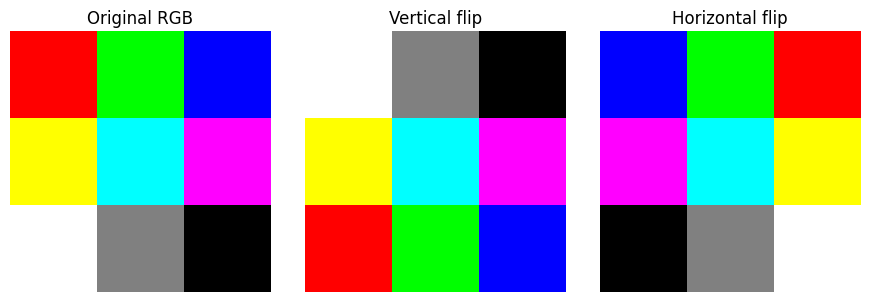

In [18]:

try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

4.1 Array Transposition

In [19]:

data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)



4.2 Transposing by Axis

In [20]:
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))


=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


5.1 Splitting Arrays (np.split)

In [21]:
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]



5.2 Stacking Arrays (np.stack)

In [22]:
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


5.3 Reshaping Split Arrays

In [23]:
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


6. Independent Student Exercises


Exercise 1 — Broadcasting in NumPy

1. Tambahkan bonus [5, 3, 2] pada setiap kolom menggunakan broadcasting.
2. Tambahkan bonus [1, 4, 2] pada setiap baris dengan reshape(-1, 1).
3. Hitung rata-rata masing-masing kolom dengan keepdims=True, lalu kurangkan dari scores.
4. Tampilkan .shape untuk setiap array bonus dan hasil perhitungan.

In [24]:
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])
print("Scores:")
print(scores)
print("Shape:", scores.shape)
print()

bonus_kolom = np.array([5, 3, 2])
print("1.Tambahkan bonus [5, 3, 2] pada setiap kolom")
print(scores+bonus_kolom)
print("Shape:", (scores+bonus_kolom).shape)
print()

bonus_baris = np.array([1, 4, 2]).reshape(-1,1)
print("2.Tambahkan bonus [1, 4, 2] pada setiap baris")
print(scores+bonus_baris)
print("Shape:", (scores+bonus_baris).shape)
print()

scores_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - scores_means
print("3.Hitung rata-rata masing-masing kolom dengan keepdims=True, lalu kurangkan dari scores")
print("Column means:", scores_means)
print("Column means shape:", scores_means.shape)
print("Centered scores:")
print(centered_scores)
print("Shape:", centered_scores.shape)
print()

print("4.Tampilkan .shape untuk setiap array bonus dan hasil perhitungan")
print("Bonus kolom:", bonus_kolom.shape)
print("Bonus baris:", bonus_baris.shape)
print("Column means:", scores_means.shape)
print("Centered scores:", centered_scores.shape)


Scores:
[[70 80 90]
 [75 85 95]
 [60 70 80]]
Shape: (3, 3)

1.Tambahkan bonus [5, 3, 2] pada setiap kolom
[[75 83 92]
 [80 88 97]
 [65 73 82]]
Shape: (3, 3)

2.Tambahkan bonus [1, 4, 2] pada setiap baris
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Shape: (3, 3)

3.Hitung rata-rata masing-masing kolom dengan keepdims=True, lalu kurangkan dari scores
Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Shape: (3, 3)

4.Tampilkan .shape untuk setiap array bonus dan hasil perhitungan
Bonus kolom: (3,)
Bonus baris: (3, 1)
Column means: (1, 3)
Centered scores: (3, 3)


Exercise 2 — Saving and Loading Arrays

1. Simpan array ke file week11_temperatures.npy menggunakan np.save().
2. Buka kembali dengan np.load() dan simpan pada variabel baru.
3. Periksa .shape, .ndim, dan .dtype dari hasil pemuatan.
4. Gunakan np.array_equal() untuk memeriksa kesamaan array asli dan hasil pemuatan.

In [25]:
temperatures = np.array([[29, 31, 30], [28, 32, 33], [27, 30, 31]])

print("1.Simpan array ke file week11_temperatures.npy menggunakan np.save()")
np.save("week11_temperatures.npy", temperatures)
print("Saved file: week11_temperatures.npy")
print("Saved array:")
print(temperatures)
print("Shape :", temperatures.shape)
print()

print("2.Buka kembali dengan np.load() dan simpan pada variabel baru")
loaded_temperatures = np.load("week11_temperatures.npy", allow_pickle=False)
print("Loaded temperatures:")
print(loaded_temperatures)
print("Loaded shape:", loaded_temperatures.shape)
print()

print("3.Periksa .shape, .ndim, dan .dtype dari hasil pemuatan")
print("Shape:", loaded_temperatures.shape)
print("Number of dimensions:", loaded_temperatures.ndim)
print("Data type:", loaded_temperatures.dtype)
print()

print("4.Gunakan np.array_equal() untuk memeriksa kesamaan array asli dan hasil pemuatan")
print("Same values and shape:", np.array_equal(temperatures, loaded_temperatures))


1.Simpan array ke file week11_temperatures.npy menggunakan np.save()
Saved file: week11_temperatures.npy
Saved array:
[[29 31 30]
 [28 32 33]
 [27 30 31]]
Shape : (3, 3)

2.Buka kembali dengan np.load() dan simpan pada variabel baru
Loaded temperatures:
[[29 31 30]
 [28 32 33]
 [27 30 31]]
Loaded shape: (3, 3)

3.Periksa .shape, .ndim, dan .dtype dari hasil pemuatan
Shape: (3, 3)
Number of dimensions: 2
Data type: int64

4.Gunakan np.array_equal() untuk memeriksa kesamaan array asli dan hasil pemuatan
Same values and shape: True


Exercise 3 — Image Arrays and Transformations

1. Tampilkan bentuk gambar dan matriks kanal Red, Green, dan Blue.
2. Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0.
3. Tambahkan kecerahan 30 pada semua kanal dengan astype(), np.clip(), dan astype(np.uint8).
4. Balik gambar secara horizontal serta vertikal menggunakan np.flip(), lalu periksa piksel pada posisi [0, 0] di setiap hasil

In [31]:
print("1.Tampilkan bentuk gambar dan matriks kanal Red, Green, dan Blue")
print("Image shape:", rgb_image.shape)
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]
print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print()

print("2.Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0")
no_blue_image = rgb_image.copy()
no_blue_image[:, :, 2] = 0
print("Blue channel setelah diubah:")
print(no_blue_image[:, :, 2])
print("Original pixel [0, 2]:", rgb_image[0, 2])
print("Pixel tanpa blue [0, 2]:", no_blue_image[0, 2])
print("Original image remains:", rgb_image[0, 2])
print()

print("3.Tambahkan kecerahan 30 pada semua kanal dengan astype(), np.clip(), dan astype(np.uint8)")
brightened_image = np.clip(rgb_image.astype(np.int16) + 30, 0, 255).astype(np.uint8)
print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [2, 2]:", rgb_image[2, 2])
print("Brighter pixel [2, 2]:", brightened_image[2, 2])
print("Data type:", brightened_image.dtype)
print()

print("4.Balik gambar secara horizontal serta vertikal menggunakan np.flip(), lalu periksa piksel pada posisi [0, 0]")
horizontal_flip = np.flip(rgb_image, axis=1)
vertical_flip = np.flip(rgb_image, axis=0)
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Horizontal flip pixel [0, 0]:", horizontal_flip[0, 0])
print("Vertical flip pixel [0, 0]:", vertical_flip[0, 0])

1.Tampilkan bentuk gambar dan matriks kanal Red, Green, dan Blue
Image shape: (3, 3, 3)
Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]

2.Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0
Blue channel setelah diubah:
[[0 0 0]
 [0 0 0]
 [0 0 0]]
Original pixel [0, 2]: [  0   0 255]
Pixel tanpa blue [0, 2]: [0 0 0]
Original image remains: [  0   0 255]

3.Tambahkan kecerahan 30 pada semua kanal dengan astype(), np.clip(), dan astype(np.uint8)
Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 30 255 255]
Original pixel [2, 2]: [0 0 0]
Brighter pixel [2, 2]: [30 30 30]
Data type: uint8

4.Balik gambar secara horizontal serta vertikal menggunakan np.flip(), lalu periksa piksel pada posisi [0, 0]
Original pixel [0, 0]: [255   0   0]
Horizontal flip pixel [0, 0]: [  0   0 255]
Vertical flip pixel [0, 0]: [255 255 255]


Exercise 4 — Transposing Arrays

1. Periksa .shape array awal.
2. Gunakan np.transpose() untuk mengubah urutan sumbu menjadi (1, 0, 2).
3. Gunakan np.swapaxes() untuk menghasilkan bentuk array yang sama.
4. Buat gambar image = np.zeros((4, 5, 3)), ubah dari HWC menjadi CHW, lalu kembalikan ke HWC.

In [30]:
arr = np.arange(24).reshape(2, 3, 4)
print("Original:")
print(arr)
print()

print("1.Periksa .shape array awal")
print("Shape:", arr.shape)
print()

print("2.Gunakan np.transpose() untuk mengubah urutan sumbu menjadi (1, 0, 2)")
print("Shape:", (np.transpose(arr, axes=(1, 0, 2))).shape)
print(np.transpose(arr, axes=(1, 0, 2)))
print()

print("3.Gunakan np.swapaxes() untuk menghasilkan bentuk array yang sama")
print("Shape:", (np.swapaxes(arr, 0, 1)).shape)
print(np.swapaxes(arr, 0, 1))
print()

print("4.Buat gambar image = np.zeros((4, 5, 3)), ubah dari HWC menjadi CHW, lalu kembalikan ke HWC")
image = np.zeros((4, 5, 3))
print("HWC shape:", image.shape)
image_chw = np.transpose(image, axes=(2, 0, 1))
print("CHW shape:", image_chw.shape)
image_back = np.transpose(image_chw, axes=(1, 2, 0))
print("Kembali ke HWC shape:", image_back.shape)
print("Sama dengan gambar awal:", np.array_equal(image, image_back))


Original:
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

1.Periksa .shape array awal
Shape: (2, 3, 4)

2.Gunakan np.transpose() untuk mengubah urutan sumbu menjadi (1, 0, 2)
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

3.Gunakan np.swapaxes() untuk menghasilkan bentuk array yang sama
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

4.Buat gambar image = np.zeros((4, 5, 3)), ubah dari HWC menjadi CHW, lalu kembalikan ke HWC
HWC shape: (4, 5, 3)
CHW shape: (3, 4, 5)
Kembali ke HWC shape: (4, 5, 3)
Sama dengan gambar awal: True


Exercise 5 — Stacking and Splitting Arrays

1. Bagi data menjadi dua bagian menurut kolom menggunakan np.split().
2. Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan reshape(-1).
3. Gabungkan kedua vektor memakai np.stack(axis=0) dan periksa bentuknya.
4. Gunakan np.array_split() untuk membagi np.arange(10) menjadi tiga bagian; bandingkan ukuran setiap bagian.


In [29]:
data = np.arange(1, 13).reshape(3, 4)
print("Original :")
print(data)
print()

print("1.Bagi data menjadi dua bagian menurut kolom menggunakan np.split()")
left_part, right_part = np.split(data, 2, axis=1)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print()

print("2.Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan reshape(-1)")
print("Left half shape:", left_part.shape)
print("Right half shape:", right_part.shape)
left_vector = left_part.reshape(-1)
right_vector = right_part.reshape(-1)
print("Left half shape after reshape:", left_vector.shape)
print(left_vector)
print("Right half shape after reshape:", right_vector.shape)
print(right_vector)
print()

print("3.Gabungkan kedua vektor memakai np.stack(axis=0) dan periksa bentuknya")
stacked = np.stack((left_vector, right_vector), axis=0)
print(stacked)
print("Shape :", stacked.shape)
print()

print("4.Gunakan np.array_split() untuk membagi np.arange(10) menjadi tiga bagian; bandingkan ukuran setiap bagian")
parts = np.array_split(np.arange(10), 3)
print("Hasil split:", [part.tolist() for part in parts])
print("Ukuran tiap bagian:", [len(part) for part in parts])

Original :
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

1.Bagi data menjadi dua bagian menurut kolom menggunakan np.split()
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]

2.Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan reshape(-1)
Left half shape: (3, 2)
Right half shape: (3, 2)
Left half shape after reshape: (6,)
[ 1  2  5  6  9 10]
Right half shape after reshape: (6,)
[ 3  4  7  8 11 12]

3.Gabungkan kedua vektor memakai np.stack(axis=0) dan periksa bentuknya
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
Shape : (2, 6)

4.Gunakan np.array_split() untuk membagi np.arange(10) menjadi tiga bagian; bandingkan ukuran setiap bagian
Hasil split: [[0, 1, 2, 3], [4, 5, 6], [7, 8, 9]]
Ukuran tiap bagian: [4, 3, 3]


Exercise 6 — Integrated Statistical Practice

Gunakan data intensitas curah hujan (baris = hari, kolom = lokasi):

1. Hitung rata-rata tiap lokasi, lalu lakukan centering menggunakan broadcasting.
2. Simpan hasil centering ke file week11_centered_rainfall.npy, kemudian muat kembali.
3. Ubah susunan data hasil pemuatan dari (hari, lokasi) menjadi (lokasi, hari) dengan .T.
4. Bagi data hasil transposisi menjadi dua bagian menurut kolom menggunakan np.split().
5. Gabungkan kembali kedua bagian dengan np.concatenate(axis=1) dan buktikan hasilnya sama dengan data sebelum dibagi.

In [28]:
rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])
print("Rainfall :")
print(rainfall)
print("Shape :", rainfall.shape)
print()

lokasi_means = np.mean(rainfall, axis=0, keepdims=True)
centering = rainfall - lokasi_means
print("1.Hitung rata-rata tiap lokasi, lalu lakukan centering menggunakan broadcasting")
print("Rata-rata tiap lokasi:", lokasi_means)
print("Hasil centering:")
print(centering)
print("Rata-rata setelah centering:", np.mean(centering, axis=0))
print()

print("2.Simpan hasil centering ke file week11_centered_rainfall.npy, kemudian muat kembali")
np.save("week11_centered_rainfall.npy", centering)
loaded_centered = np.load("week11_centered_rainfall.npy", allow_pickle=False)
print("Loaded shape:", loaded_centered.shape)
print("Sama dengan sebelum disimpan:", np.array_equal(centering, loaded_centered))
print()
print()

transposed_rainfall = loaded_centered.T
print("3.Ubah susunan data hasil pemuatan dari (hari, lokasi) menjadi (lokasi, hari) dengan .T")
print("Shape:", transposed_rainfall.shape)
print(transposed_rainfall)
print()

print("4.Bagi data hasil transposisi menjadi dua bagian menurut kolom menggunakan np.split()")
first_part, second_part = np.split(transposed_rainfall, 2, axis=1)
print("First part shape:", first_part.shape)
print(first_part)
print("Second part shape:", second_part.shape)
print(second_part)
print()

print("5.Gabungkan kembali kedua bagian dengan np.concatenate(axis=1) dan buktikan hasilnya sama dengan data sebelum dibagi")
gabung = np.concatenate((first_part, second_part), axis=1)
print("Shape gabungan:", gabung.shape)
print(gabung)
print("Sama dengan data sebelum dibagi:", np.array_equal(gabung, transposed_rainfall))


Rainfall :
[[12  8  5]
 [10 15  7]
 [20 11  9]
 [ 8  6  4]]
Shape : (4, 3)

1.Hitung rata-rata tiap lokasi, lalu lakukan centering menggunakan broadcasting
Rata-rata tiap lokasi: [[12.5  10.    6.25]]
Hasil centering:
[[-0.5  -2.   -1.25]
 [-2.5   5.    0.75]
 [ 7.5   1.    2.75]
 [-4.5  -4.   -2.25]]
Rata-rata setelah centering: [0. 0. 0.]

2.Simpan hasil centering ke file week11_centered_rainfall.npy, kemudian muat kembali
Loaded shape: (4, 3)
Sama dengan sebelum disimpan: True


3.Ubah susunan data hasil pemuatan dari (hari, lokasi) menjadi (lokasi, hari) dengan .T
Shape: (3, 4)
[[-0.5  -2.5   7.5  -4.5 ]
 [-2.    5.    1.   -4.  ]
 [-1.25  0.75  2.75 -2.25]]

4.Bagi data hasil transposisi menjadi dua bagian menurut kolom menggunakan np.split()
First part shape: (3, 2)
[[-0.5  -2.5 ]
 [-2.    5.  ]
 [-1.25  0.75]]
Second part shape: (3, 2)
[[ 7.5  -4.5 ]
 [ 1.   -4.  ]
 [ 2.75 -2.25]]

5.Gabungkan kembali kedua bagian dengan np.concatenate(axis=1) dan buktikan hasilnya sama dengan d